# Project 1: Big Data Programming Paradigms

Vinicius Trindade Dias Abel - 2020007112

## Initial settings

In [ ]:
import os
import sys
import glob

os.environ["JAVA_HOME"] = "/usr/lib/jvm/temurin-11-jdk-amd64"
os.environ["HADOOP_HOME"] = "/opt/hadoop"
os.environ["SPARK_HOME"] = "/opt/spark"

sys.path.insert(0, os.path.join(os.environ["SPARK_HOME"], "python"))
for fp in glob.iglob(os.environ["SPARK_HOME"] + "/python/lib/*.zip"):
  sys.path.append(fp)

In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("TP1 - Spotify") \
    .config("spark.executor.instances", "2") \
    .config("spark.executor.cores", "2") \
    .config("spark.executor.memory", "1024M") \
    .getOrCreate()

sc = spark.sparkContext

sc.setLogLevel("ERROR")

print(f"Spark UI available on: {sc.uiWebUrl}")

25/09/29 00:10:24 WARN Utils: Your hostname, cloud251 resolves to a loopback address: 127.0.1.1; using 192.168.121.49 instead (on interface eth0)
25/09/29 00:10:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/09/29 00:10:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark UI available on: http://192.168.121.49:4040


## Dataset

In [3]:
# Load the dataset
playlists_df = spark.read.json("hdfs://localhost:9000/datasets/spotify/playlist.json")
tracks_df = spark.read.json("hdfs://localhost:9000/datasets/spotify/tracks.json")

In [4]:
# Show the schema of the DataFrames
print("Playlists Schema:")
playlists_df.printSchema()
print("Tracks Schema:")
tracks_df.printSchema()

Playlists Schema:
root
 |-- collaborative: string (nullable = true)
 |-- description: string (nullable = true)
 |-- duration_ms: long (nullable = true)
 |-- modified_at: long (nullable = true)
 |-- name: string (nullable = true)
 |-- num_albums: long (nullable = true)
 |-- num_artists: long (nullable = true)
 |-- num_edits: long (nullable = true)
 |-- num_followers: long (nullable = true)
 |-- num_tracks: long (nullable = true)
 |-- pid: long (nullable = true)

Tracks Schema:
root
 |-- album_name: string (nullable = true)
 |-- album_uri: string (nullable = true)
 |-- artist_name: string (nullable = true)
 |-- artist_uri: string (nullable = true)
 |-- duration_ms: long (nullable = true)
 |-- pid: long (nullable = true)
 |-- pos: long (nullable = true)
 |-- track_name: string (nullable = true)
 |-- track_uri: string (nullable = true)



In [5]:
# Show sample data
print("Playlists Sample Data:")
playlists_df.show(5)
print("Tracks Sample Data:")
tracks_df.show(5)

Playlists Sample Data:
+-------------+-----------+-----------+-----------+----------------+----------+-----------+---------+-------------+----------+---+
|collaborative|description|duration_ms|modified_at|            name|num_albums|num_artists|num_edits|num_followers|num_tracks|pid|
+-------------+-----------+-----------+-----------+----------------+----------+-----------+---------+-------------+----------+---+
|        false|       NULL|   11532414| 1493424000|      Throwbacks|        47|         37|        6|            1|        52|  0|
|        false|       NULL|   11656470| 1506556800|Awesome Playlist|        23|         21|        5|            1|        39|  1|
|        false|       NULL|   14039958| 1505692800|         korean |        51|         31|       18|            1|        64|  2|
|        false|       NULL|   28926058| 1501027200|             mat|       107|         86|        4|            1|       126|  3|
|        false|       NULL|    4335282| 1401667200|         

## 1. Statistics about songs duration

### 1. Generate a table containing the minimum, average and maximum duration, in milliseconds, of the songs in the dataset.

In [6]:
from pyspark.sql.functions import min, avg, max

# Calculate statistics for song durations
duration_stats_df = tracks_df.select(
    min("duration_ms").alias("Minimum duration (ms)"),
    avg("duration_ms").alias("Average duration (ms)"),
    max("duration_ms").alias("Maximum duration (ms)")
)

# Show the results table
print("Table 1: Song Duration Statistics")
duration_stats_df.show()

Table 1: Song Duration Statistics


+---------------------+---------------------+---------------------+
|Minimum duration (ms)|Average duration (ms)|Maximum duration (ms)|
+---------------------+---------------------+---------------------+
|                    0|   234408.54976216817|             10435467|
+---------------------+---------------------+---------------------+



### 2. Compute the first and third quartiles (denoted Q1 and Q3), as well as the interquartile range (IRQ) (Q3 − Q1).

In [7]:
# Calculate quartiles for song durations
quartiles = tracks_df.approxQuantile("duration_ms", [0.25, 0.75], 0.01)

q1 = quartiles[0]
q3 = quartiles[1]

# Calculate IQR
iqr = q3 - q1

print(f"First Quartile (Q1): {q1:.2f} ms")
print(f"Third Quartile (Q3): {q3:.2f} ms")
print(f"Interquartile Range (IQR): {iqr:.2f} ms")

First Quartile (Q1): 198026.00 ms
Third Quartile (Q3): 258133.00 ms
Interquartile Range (IQR): 60107.00 ms


### 3. Compute the set of songs with durations that are not outliers, as defined by the IQRR methodology. In other words, identify all songs with duration x such that Q1 − 1.5 * IQR < X < Q3 + 1.5 * IQR.

In [8]:
# Determine outlier boundaries
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Lower Bound: {lower_bound:.2f} ms")
print(f"Upper Bound: {upper_bound:.2f} ms")

# Filter out outliers
tracks_non_outliers_df = tracks_df.filter(
    (tracks_df["duration_ms"] > lower_bound) & (tracks_df["duration_ms"] < upper_bound)
)

Lower Bound: 107865.50 ms
Upper Bound: 348293.50 ms


### 4. Using the IQRR methodology, how many songs would be considered outliers and removed from analysis? Generate a new table containing the minimum, average and maximum duration of the remaining songs.

In [9]:
# Calculate statistics for non-outlier song durations
total_count = tracks_df.count()
non_outlier_count = tracks_non_outliers_df.count()
outlier_count = total_count - non_outlier_count

print(f"\nTotal number of songs: {total_count}")
print(f"Number of songs without outliers: {non_outlier_count}")
print(f"Total outliers removed: {outlier_count}")


Total number of songs: 10760544
Number of songs without outliers: 10189635
Total outliers removed: 570909


In [10]:
# Calculate statistics for song durations without outliers
final_duration_stats_df = tracks_non_outliers_df.select(
    min("duration_ms").alias("Minimum duration (ms)"),
    avg("duration_ms").alias("Average duration (ms)"),
    max("duration_ms").alias("Maximum duration (ms)")
)

# Show the results table
print("Table 2: Non-Outlier Song Duration Statistics")
final_duration_stats_df.show()

Table 2: Non-Outlier Song Duration Statistics


+---------------------+---------------------+---------------------+
|Minimum duration (ms)|Average duration (ms)|Maximum duration (ms)|
+---------------------+---------------------+---------------------+
|               107866|    226795.8593433425|               348293|
+---------------------+---------------------+---------------------+



### Abordagem 

Para esta tarefa, o objetivo foi analisar a distribuição da duração das músicas e remover valores atípicos (outliers). 

A abordagem foi a seguinte:

1. O DataFrame de músicas ```tracks_df``` foi utilizado como base.
2. Inicialmente, foram calculadas as estatísticas descritivas (mínimo, média e máximo) da coluna ```duration_ms``` para obter uma visão geral dos dados.
3. Como método de pós-processamento, foi aplicada a Regra do Intervalo Interquartil (IQRR) para identificar e filtrar os outliers.
4. Os primeiro (Q1) e terceiro (Q3) quartis foram calculados utilizando a função ```approxQuantile``` do Spark, com uma margem de erro de ```0.01``` para garantir eficiência computacional.
5. Com base no IQR (Q3 − Q1), os limites inferior (Q1 − 1.5 × IQR) e superior (Q3 + 1.5 × IQR) foram definidos.
6. Um novo DataFrame foi criado utilizando a função ```.filter()```, mantendo apenas as músicas com duração dentro desses limites.
7. Por fim, o número de outliers removidos foi contabilizado e as mesmas estatísticas descritivas foram recalculadas sobre o conjunto de dados filtrado.

### Resultados

Tabela 1: Estatísticas Iniciais de Duração das Músicas

<table>
  <tr>
    <th>Duração Mínima (ms)</th>
    <th>Duração Média (ms)</th>
    <th>Duração Máxima (ms)</th>
  </tr>
  <tr>
    <td>0</td>
    <td>234.408,54976216817</td>
    <td>10.435.467</td>
  </tr>
</table>

Tabela 2: Estatísticas de Duração das Músicas (Sem Outliers)

<table>
  <tr>
    <th>Duração Mínima (ms)</th>
    <th>Duração Média (ms)</th>
    <th>Duração Máxima (ms)</th>
  </tr>
  <tr>
    <td>107.866</td>
    <td>226.795,8593433425</td>
    <td>348.293</td>
  </tr>
</table>

A análise inicial (Tabela 1) revela uma variação muito grande na duração das músicas. A presença de uma duração mínima de ```0ms``` sugere faixas sem conteúdo ou erros nos dados, enquanto a duração máxima de ```10.435.467ms``` (aproximadamente 174 minutos) indica a presença de outliers significativos, como mixes longos ou shows completos, que distorcem a percepção de uma música típica. A aplicação da metodologia IQRR resultou na remoção de ```570.909``` faixas. 

A Tabela 2 mostra o impacto da remoção dos outliers. A duração máxima foi reduzida para ```348.293ms``` (cerca de 5,8 minutos), um valor muito mais condizente com uma música padrão. A duração média também reduziu um pouco, ficando mais representativa. E a duração mínima não considera faixas sem conteúdo.

Portanto, o conjunto de dados filtrado oferece uma base mais confiável e realista para análises sobre a duração de músicas típicas na plataforma.

## 2. Finding the most popular artists over time

In [11]:
# Join the DataFrames on "pid"
joined_df = tracks_df.join(playlists_df, "pid", "inner")

joined_df.printSchema()

root
 |-- pid: long (nullable = true)
 |-- album_name: string (nullable = true)
 |-- album_uri: string (nullable = true)
 |-- artist_name: string (nullable = true)
 |-- artist_uri: string (nullable = true)
 |-- duration_ms: long (nullable = true)
 |-- pos: long (nullable = true)
 |-- track_name: string (nullable = true)
 |-- track_uri: string (nullable = true)
 |-- collaborative: string (nullable = true)
 |-- description: string (nullable = true)
 |-- duration_ms: long (nullable = true)
 |-- modified_at: long (nullable = true)
 |-- name: string (nullable = true)
 |-- num_albums: long (nullable = true)
 |-- num_artists: long (nullable = true)
 |-- num_edits: long (nullable = true)
 |-- num_followers: long (nullable = true)
 |-- num_tracks: long (nullable = true)



In [12]:
from pyspark.sql.functions import countDistinct, desc

# Find the top 5 most popular artists by the number of playlists they appear in
top_artists_df = joined_df.groupBy("artist_name") \
    .agg(countDistinct("pid").alias("playlist_count")) \
    .orderBy(desc("playlist_count")) \
    .limit(5)

print("Top 5 Most Popular Artists by Playlist Count:")
top_artists_df.show()

top_5_artists_list = [row.artist_name for row in top_artists_df.collect()]

Top 5 Most Popular Artists by Playlist Count:


+--------------+--------------+
|   artist_name|playlist_count|
+--------------+--------------+
|         Drake|         32259|
|       Rihanna|         23963|
|    Kanye West|         22464|
|    The Weeknd|         20046|
|Kendrick Lamar|         19159|
+--------------+--------------+



In [13]:
from pyspark.sql.functions import col, year, from_unixtime

# Prepare data for plotting playlist counts over time for the top 5 artists
plot_data_df = joined_df \
    .filter(col("artist_name").isin(top_5_artists_list)) \
    .withColumn("year", year(from_unixtime(col("modified_at")))) \
    .groupBy("year", "artist_name") \
    .agg(countDistinct("pid").alias("playlist_count")) \
    .orderBy("year", "artist_name")

print("Playlist Counts Over Time for Top 5 Artists:")
plot_data_df.show()

Playlist Counts Over Time for Top 5 Artists:


+----+--------------+--------------+
|year|   artist_name|playlist_count|
+----+--------------+--------------+
|2011|    Kanye West|             4|
|2011|       Rihanna|             1|
|2012|         Drake|            24|
|2012|    Kanye West|            25|
|2012|Kendrick Lamar|             5|
|2012|       Rihanna|            31|
|2012|    The Weeknd|             2|
|2013|         Drake|           523|
|2013|    Kanye West|           463|
|2013|Kendrick Lamar|           279|
|2013|       Rihanna|           506|
|2013|    The Weeknd|            99|
|2014|         Drake|           880|
|2014|    Kanye West|           820|
|2014|Kendrick Lamar|           506|
|2014|       Rihanna|           795|
|2014|    The Weeknd|           212|
|2015|         Drake|          2517|
|2015|    Kanye West|          1880|
|2015|Kendrick Lamar|          1304|
+----+--------------+--------------+
only showing top 20 rows



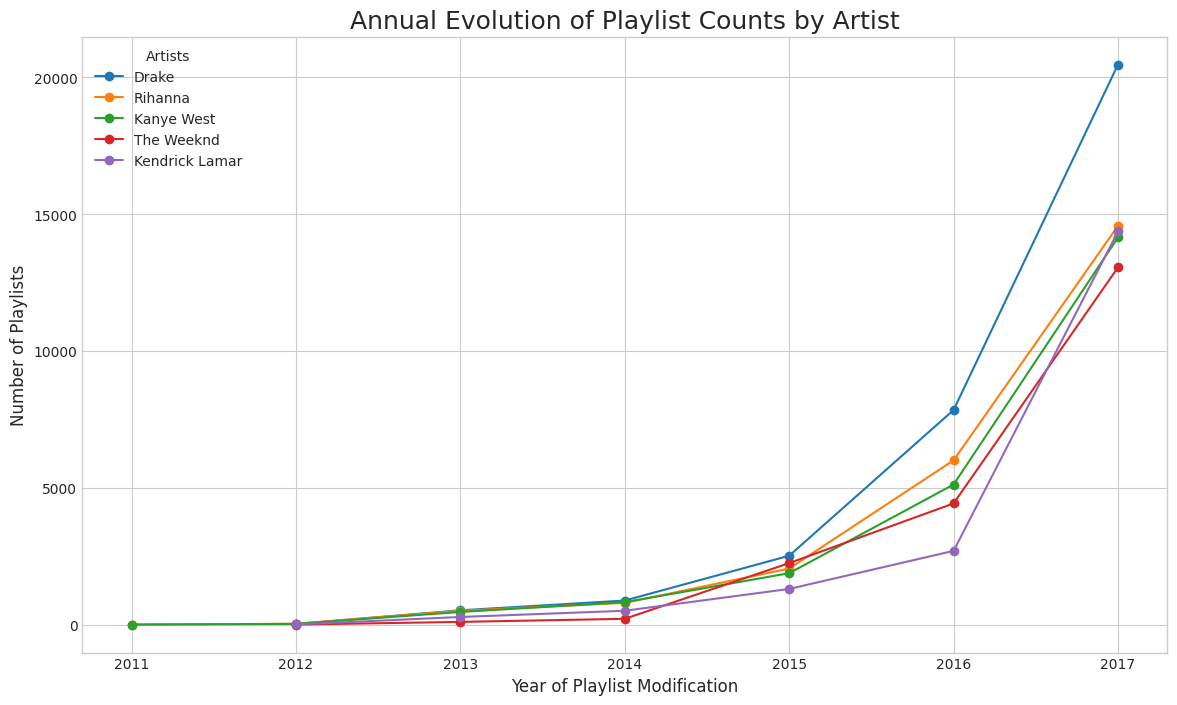

In [14]:
import matplotlib.pyplot as plt

# Convert to Pandas for plotting
plot_pandas_df = plot_data_df.toPandas()

# Plotting
plt.style.use('seaborn-v0_8-whitegrid') 
fig, ax = plt.subplots(figsize=(14, 8)) 

for artist in top_5_artists_list:
    
    artist_df = plot_pandas_df[plot_pandas_df['artist_name'] == artist]
    
    ax.plot(artist_df['year'], artist_df['playlist_count'], marker='o', linestyle='-', label=artist)

ax.set_title('Annual Evolution of Playlist Counts by Artist', fontsize=18)
ax.set_xlabel('Year of Playlist Modification', fontsize=12)
ax.set_ylabel('Number of Playlists', fontsize=12)
ax.legend(title='Artists', fontsize=10)
ax.grid(True) 

plt.show()

### Abordagem 

O objetivo desta tarefa foi identificar os cinco artistas mais populares e visualizar sua popularidade ao longo dos anos. A popularidade foi definida pelo número de playlists distintas em que um artista aparece. 

A abordagem foi a seguinte:

1. Os DataFrames de músicas e playlists foram combinados (```.join()```) utilizando o ID da playlist (```pid```) como chave.
2. Para determinar os artistas mais populares, os dados foram agrupados por ```artist_name```, e a contagem de ```pids``` distintos foi calculada para cada um. O resultado foi ordenado de forma decrescente e os 5 primeiros foram selecionados.
3. Em seguida, o DataFrame unido foi filtrado para conter apenas dados desses cinco artistas.
4. Uma nova coluna ```year``` foi extraída da coluna ```modified_at``` (timestamp UNIX) para permitir a agregação anual.
5. Os dados foram então agrupados por ```year``` e ```artist_name```, e uma nova contagem de playlists distintas foi realizada para obter a popularidade anual de cada artista.
6. Para o resultado final, um ```DataFrame Spark``` de tamanho reduzido, foi convertido para um ```DataFrame Pandas``` e plotado com a biblioteca ```matplotlib```, gerando um gráfico de linhas.

### Resultados

O gráfico acima ilustra a evolução da popularidade dos cinco artistas mais presentes em playlists no dataset: Drake, Rihanna, Kanye West, The Weeknd e Kendrick Lamar. É notável um crescimento geral na presença de todos os artistas em playlists ao longo dos anos, o que indica a expansão da base de usuários do Spotify no período analisado (2010-2017). Drake demonstra uma liderança consistente e um crescimento acentuado, destacando-se como o artista mais popular na maior parte do período. Os outros artistas também demonstram crescimento na popularidade, e o número de playlists em que aparecem são semelhantes ao final do período analisado, mas não se aproximam dos resultados alcançados por Drake.

## 3. Playlists's behavior

In [15]:
from pyspark.sql.functions import count

# Calculate total tracks counts per playlist
total_tracks_per_playlist_df = tracks_df.groupBy("pid") \
    .agg(count("*").alias("total_tracks"))

# Calculate artist track counts per playlist
artist_counts_per_playlist_df = tracks_df.groupBy("pid", "artist_name") \
    .agg(count("*").alias("artist_track_count"))

In [16]:
from pyspark.sql.functions import max as spark_max

# Find the maximum artist track count per playlist
top_artist_counts_df = artist_counts_per_playlist_df.groupBy("pid") \
    .agg(spark_max("artist_track_count").alias("top_artist_track_count"))

top_artist_counts_df.show(5)

+----+----------------------+
| pid|top_artist_track_count|
+----+----------------------+
|  26|                     4|
|  29|                     2|
| 964|                     7|
|1677|                     4|
|1697|                     2|
+----+----------------------+
only showing top 5 rows



In [17]:
# Create prevalence DataFrame
prevalence_df = total_tracks_per_playlist_df.join(
    top_artist_counts_df,
    "pid",
    "inner"
)

prevalence_df = prevalence_df.withColumn(
    "prevalence",
    col("top_artist_track_count") / col("total_tracks")
)

prevalence_df.select("pid", "prevalence").show(5)

+----+-------------------+
| pid|         prevalence|
+----+-------------------+
|  26|0.15384615384615385|
|  29|               0.05|
| 964|0.05185185185185185|
|1677|0.14814814814814814|
|1697|0.18181818181818182|
+----+-------------------+
only showing top 5 rows



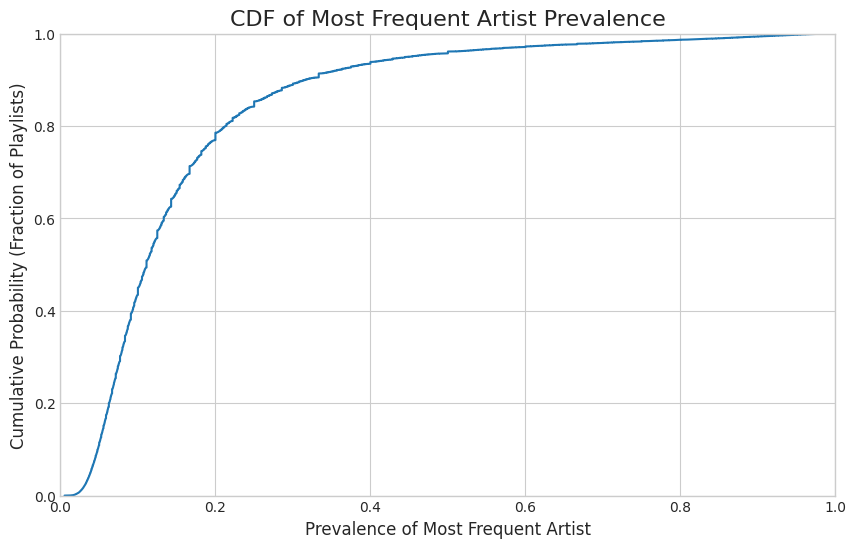

In [18]:
import numpy as np

# Collect prevalence values to the driver
prevalence_values = prevalence_df.select("prevalence").rdd.flatMap(lambda row: row).collect()

# Sort the prevalence values
prevalence_sorted = np.sort(prevalence_values)

# Calculate the CDF values
y_vals = np.arange(1, len(prevalence_sorted) + 1) / len(prevalence_sorted)

# Plotting the CDF
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(prevalence_sorted, y_vals)

ax.set_title('CDF of Most Frequent Artist Prevalence', fontsize=16)
ax.set_xlabel('Prevalence of Most Frequent Artist', fontsize=12)
ax.set_ylabel('Cumulative Probability (Fraction of Playlists)', fontsize=12)
ax.grid(True)
ax.set_xlim(0, 1) 
ax.set_ylim(0, 1)

plt.show()

### Abordagem

Esta tarefa buscou responder se as playlists do Spotify são, em geral, musicalmente diversas ou focadas em poucos artistas. Para isso, foi calculada a "prevalência" do artista mais frequente em cada playlist. 

A abordagem foi a seguinte:

1. A partir do ```tracks_df```, foram realizadas duas agregações iniciais: o número total de músicas por playlist e o número de músicas por artista dentro de cada playlist.
2. A partir da segunda agregação, foi calculada a contagem máxima de músicas de um único artista para cada playlist.
3. Esses dois resultados foram unidos pelo ID da playlist, permitindo o cálculo da prevalência, definida como a fração da contagem do artista mais frequente pelo total de músicas na playlist.
4. Todos os valores de prevalência foram coletados do ```DataFrame Spark``` para uma lista em Python.
5. Utilizando as bibliotecas ```numpy``` e ```matplotlib```, os dados foram ordenados e plotados como uma Função de Distribuição Cumulativa (CDF), que visualiza a distribuição de probabilidade dos valores de prevalência.


### Resultados

O gráfico da Função de Distribuição Cumulativa (CDF) acima responde à pergunta central da tarefa. A forma da curva, que sobe acentuadamente no lado esquerdo, indica que a grande maioria das playlists possui um baixo valor de prevalência do artista mais frequente. Analisando o gráfico, é possível observar que aproximadamente 80% das playlists (eixo Y em 0.8) apresentam uma prevalência de 0.2 ou menos (eixo X em 0.2). Isso significa que, em 80% dos casos, o artista mais popular em uma playlist é responsável por, no máximo, 20% de suas músicas. Este resultado demonstra que o comportamento predominante dos usuários ao criar playlists é o de agregar músicas de uma grande variedade de artistas, favorecendo a diversidade musical, e não reunir músicas apenas de um mesmo artista.